In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from typing import Tuple
from tqdm import tqdm
import pandas as pd
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

ruta_scripts = Path.cwd().parent / "scripts"
sys.path.append(str(ruta_scripts))

import Modelos_neuronales as mn

import jpype
import os
from jpype import JClass

jar_path = os.path.abspath("infodynamics.jar")
jpype.startJVM(classpath=[jar_path])

TECalcClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").TransferEntropyCalculatorKraskov
teCalc = TECalcClass()

from jpype import JPackage
CTEClass = JPackage("infodynamics.measures.continuous.kraskov").ConditionalTransferEntropyCalculatorKraskov
cteCalc = CTEClass()

MIClass = jpype.JPackage("infodynamics.measures.continuous.kraskov").MutualInfoCalculatorMultiVariateKraskov1
miCalc = MIClass()


from statsmodels.tsa.api import VAR
from sklearn.feature_selection import mutual_info_regression

## Retardo Causal

El presente notebook se reserva al importante estudio de la búsqueda del retardo causal en los experimento de flujo de información. Es importante aplicar los estimadores en el instante de tiempo correcto porque si no las conclusiones y resultados no tendrán validez al estar aplicadas en el lugar erróneo.

En esta breve batería de pruebas se puede observar que los estimadores de IM y TE se tratan de manera similar. La ausencia de métodos internos para llevar a cabo la elección del retardo óptimo nos ha llevado a la creación de dos funciones; `find_optimal_tau_MI` y `find_optimal_tau_TE_JIDT`, que generan una gráfica del valor del estimador en función del delay aplicado, de modo que se manifiestan los retardos donde se halla un mayor flujo de información. El valor más alto detectado de IM o TE se devuelve como salida haciendo explícito el retardo que optimiza dicho estimador.
La diferencia entre ambos modelos radica en el método de aplicar el retardo en los estimadores. Para el caso de la IM, la herramienta `mutual_info_regression` de scikit-learn calcula el valor del estimador sin tener en cuenta de forma explícita el retardo causal. Esto se debe a la cerencia de direccionalidad y simetría del estimador, que provoca un déficit en el análisis interno del flujo de información. Para optimizar el recurso, la función `find_optimal_tau_MI` genera un desplazamiento de una serie temporal respecto a la otra y calcula el valor de la IM para cada valor de retardo aplicado de ese modo.
Sin embargo, el estimador de Transfer Entropy `JIDT` de Google Code si permite definir un retrado causal de forma explícita para realizar el análisis. En este caso, el estimador está diseñado para analizar direccionalidad y temporalidad del flujo de información.

Para el caso de la Granger Causality, el estudio se centraliza sobre las posibilidades que ofrece el recurso `VAR`de la librería `statsmodels`. En este caso, el valor del retardo causal se asocia directamente con los parámetros estructurales del modelo autorregesivo que presupone el estimador para los datos. La importnacia de este factor estructural hace determinante la elección del retado y la herramienta pone a disposición criterios de información diseñados para ese análisis.  

### Información Mutua y Transfer Entropy

A continuación se muestran las dos funciones comentadas anteriormente. Ambas funciones calculan la medida de sus estimadores con valores de retardo hasta el que se haya especificado como entrada.

In [3]:
def find_optimal_tau_MI(V1, V2, n_vecinos, dt=0.01, max_lags=600, milisegundos = True, plot=False):
    """
    Calcula la Información Mutua para diferentes retardos (tau). El retardo consiste en desplazar V2 respecto a V1.
    """
    
    lags = np.arange(0, max_lags)
    mi_results = []
    factor=5 

    v1_fixed = V1[:-(max_lags)]
    
    for lag in tqdm(lags, desc="Análisis de Tau", unit="lag"):
        v2_shifted = V2[lag : lag + len(v1_fixed)]
        
        mi = mutual_info_regression(v1_fixed[::factor].reshape(-1, 1), v2_shifted[::factor], n_neighbors= n_vecinos, discrete_features=False)
        mi_results.append(mi[0])
        
    mi_results = np.array(mi_results)
    
    # Encontrar el óptimo
    optimal_idx = np.argmax(mi_results)
    optimal_tau = lags[optimal_idx]

    if milisegundos:
        x_values = lags * dt
        optimal_tau = optimal_tau *dt
        xlabel = r"$\tau$ (ms)"
    else:
        x_values = lags
        xlabel = r"$\tau$ (pasos)"

    # Gráfica
    if plot:

        plt.figure(figsize=(10, 6))
        plt.plot(x_values, mi_results, lw=2, label="Información mutua")
        plt.scatter(x_values[optimal_idx], mi_results[optimal_idx], marker="*", s=250, zorder=5, label=f"Óptimo: τ={optimal_tau:.3f}")
        plt.axvline( x_values[optimal_idx], linestyle="--", alpha=0.7)
        plt.xlabel(xlabel)
        plt.ylabel("Mutual Information")
        plt.title(
            f"MI vs τ (k={n_vecinos})"
        )
        plt.grid(True)
        plt.legend()
        plt.show()
        
    return mi_results, optimal_tau

In [4]:
def find_optimal_tau_TE_JIDT(V1, V2, n_vecinos, max_steps=600, contexto_k=5, contexto_l=5, contexto_c=50, factor_bool=True, plot=False, inverse=False, conditional=False, padres_source=None):
    """
    Calcula la Transfer Entropy (TE) para distintos valores de tau_source con el código de JIDT.
    Si inverse=True:
        calcula también V2 -> V1.
    Si conditional=True:
        calcula también la CTE V1 -> V2 | V2
    Retorna:
        tau_values, te_direct, optimal_tau

    """
    tau_values = np.arange(1, max_steps + 1)
    te_results = []

    if inverse:
        te_inverse_results = []
        
    if conditional:
        cte_results = []
    
    factor = 5   

    if factor_bool:
        V1 = V1[::factor]
        V2 = V2[::factor]

    hist = max(contexto_k, contexto_l, contexto_c)
    V1 = V1[hist:]
    V2 = V2[hist:]

        
        # --- TE Directa (V1 -> V2) ---
    teCalc = TECalcClass()
    teCalc.setProperty("k", str(n_vecinos))
    teCalc.setProperty("k_HISTORY", str(contexto_k))
    teCalc.setProperty("l_HISTORY", str(contexto_l))
    

    for tau in tqdm(tau_values, desc="Análisis de Tau", unit="tau"):
        
        teCalc.setProperty("DELAY", str(tau))
        teCalc.initialise()
        teCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64))
        te = teCalc.computeAverageLocalOfObservations()
        te_results.append(te)

         # --- TE Inversa (V2 -> V1) ---
    if inverse:
    
            teCalc_inv = TECalcClass()
            teCalc_inv.setProperty("k", str(n_vecinos))
            teCalc_inv.setProperty("k_HISTORY", str(contexto_k))
            teCalc_inv.setProperty("l_HISTORY", str(contexto_l))
    
            for tau in tqdm(tau_values, desc="TE V2 → V1", unit="tau"):
                teCalc_inv.setProperty("DELAY", str(tau))
                teCalc_inv.initialise()
                teCalc_inv.setObservations(V2.astype(np.float64),V1.astype(np.float64))
                te_inv = teCalc_inv.computeAverageLocalOfObservations()
                te_inverse_results.append(te_inv)
                

        # --- CTE (V1 -> V2 | V2) ---
    if conditional:
        cteCalc = CTEClass() 
        cteCalc.setProperty("k", str(n_vecinos))
        cteCalc.setProperty("k_HISTORY", str(contexto_k))
        cteCalc.setProperty("l_HISTORY", str(contexto_l))
        cteCalc.setProperty("c_HISTORY", str(contexto_c))
    
        for tau in tqdm(tau_values, desc="CTE V1 → V2 | V2", unit="tau"):
            cteCalc.setProperty("DELAY", str(tau))
            cteCalc.initialise()
            cteCalc.setObservations(V1.astype(np.float64), V2.astype(np.float64), V2.astype(np.float64))
            cte_val = cteCalc.computeAverageLocalOfObservations()
            cte_results.append(cte_val)


    te_results = np.array(te_results)
    if inverse:
        te_inverse_results = np.array(te_inverse_results)
    if conditional:
        cte_results = np.array(cte_results)

    optimal_idx = np.argmax(te_results)
    optimal_tau = tau_values[optimal_idx]
    
    if factor_bool:
        optimal_tau = optimal_tau * factor
        tau_values = tau_values * factor

    # Gráfica
    if plot:

        plt.figure(figsize=(10, 6))
        plt.plot(tau_values, te_results, lw=2, label="Transfer Entropy (Direct)")
        if padres_source is not None:
            if np.isscalar(padres_source):
                padres_source = [padres_source]
            for i, delay in enumerate(padres_source):
                if delay in tau_values:
                    idx = np.where(tau_values == delay)[0][0]
                    plt.scatter(tau_values[idx], te_results[idx], marker="*", s=250, zorder=5, label="Padre seleccionado" if i == 0 else None)
        if inverse:
            plt.plot(tau_values, te_inverse_results, color="gray", alpha=0.45, lw=1.8, linestyle="--", label="TE V2 → V1")
        if conditional:
            plt.plot(tau_values, cte_results, color="red", alpha=0.35, lw=1.8, linestyle="--", label="CTE V1 → V2 | V2")
        plt.axvline(tau_values[optimal_idx], linestyle="--", alpha=0.7)
        plt.xlabel("Delay")
        plt.ylabel("Transfer Entropy")
        plt.title(f"TE (JIDT-Kraskov) vs Delay "f"(k={n_vecinos})")
        plt.grid(True)
        plt.legend()
        plt.show()


    return tau_values, te_results, optimal_tau

Se usará el sistema VAR($\tau$):
$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y 
\end{cases}
$$
para realizar los primeros experimentos sobre una base teórica en la que se conoce el valor del retardo causal; $\tau$. De ese modo se certifica la validez de las funciones utilizadas. Se definen las variables para $\tau = 133$:

In [20]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 133

T = 5000

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(tau, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
X = data['X'].values
Y = data['Y'].values

Análisis de Tau: 100%|██████████| 350/350 [00:08<00:00, 41.02lag/s]


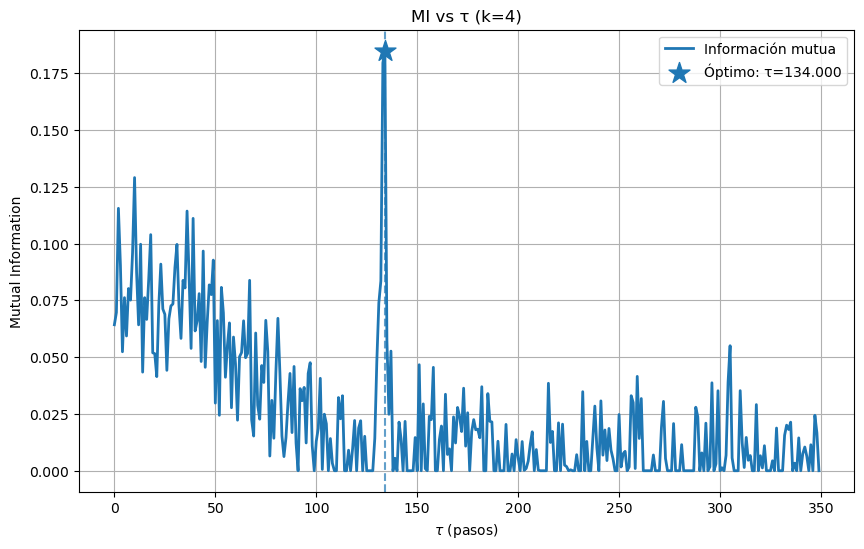

El desplazamiento óptimo para número de vecinos k=4 es: 134


In [25]:
mis, best_tau = find_optimal_tau_MI(Y, X, n_vecinos=4, max_lags=350, milisegundos = False, plot= True)
print(f"El desplazamiento óptimo para número de vecinos k={4} es: {best_tau}")

Análisis de Tau: 100%|██████████| 350/350 [04:18<00:00,  1.35tau/s]


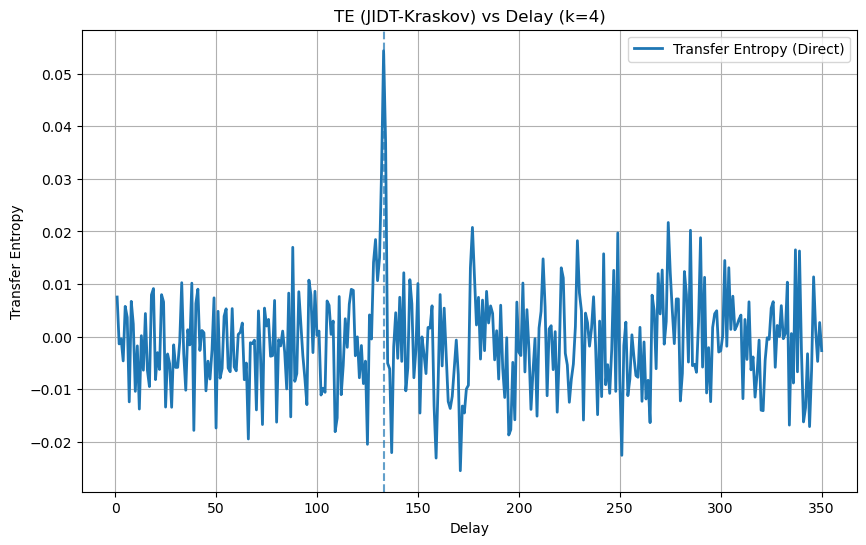

El delay óptimo para k=4 es: 133.000 ms


In [12]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(Y, X, n_vecinos=4, max_steps=350, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Análisis de Tau: 100%|██████████| 350/350 [01:56<00:00,  3.00tau/s]


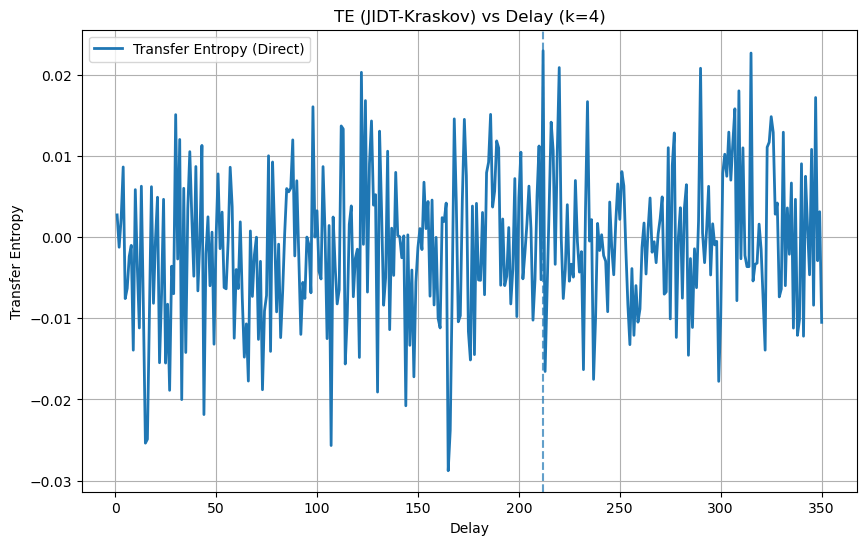

El delay óptimo para k=4 es: 212.000 ms


In [21]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(X, Y, n_vecinos=4, max_steps=350, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Estos dos experimentos demuestran que `find_optimal_tau_MI` y `find_optimal_tau_TE_JIDT` detectan correctamente el desplazamiento/retardo ótimo que se debe aplicar en las medidas MI/TE respectivamente. Por ahora, nos permite observar la presencia de ruido controlado en ambos estimadores y una tendencia a sobrestimación inicial de la IM. Al aplicar el estimador de TE sobre las muestras, pero en sentido contrario, observamos el margen de ruido que presenta el estimador por defecto.


Veamos su desempeño ante simulaciones de neuronas.

### Simulación tipo Izhikevich

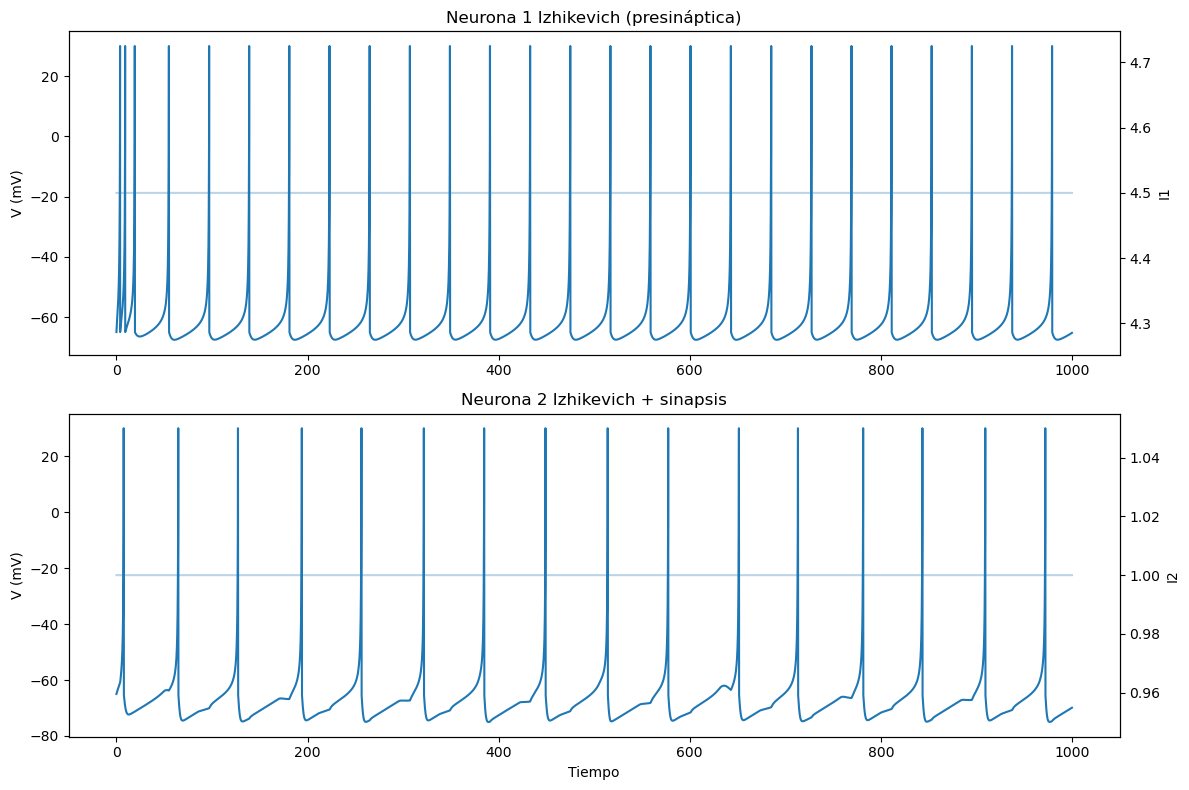

In [44]:
V1, V2= mn.izhikevich(T = 1000, a1= 0.01, b1= 0.26, c1= -65.0, d1= 2.0, a2 = 0.02, b2= 0.25, c2 = -65.0, d2 = 6.0, I1_const = 4.5, I2_const = 1.0, g_syn = 0.1, tau_delay = 0.0, plot = True)

Análisis de Tau: 100%|██████████| 550/550 [00:23<00:00, 23.55lag/s]


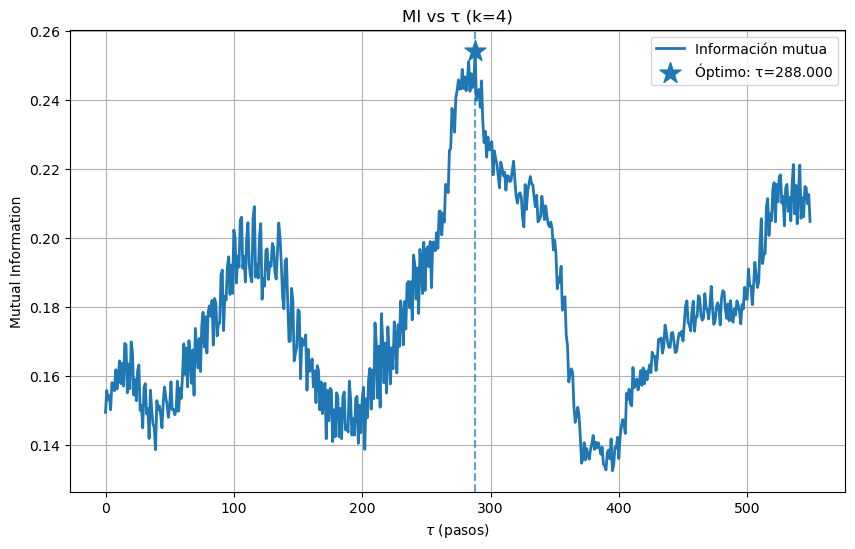

El desplazamiento óptimo para número de vecinos k=4 es: 288


In [27]:
mis, best_tau = find_optimal_tau_MI(V1, V2, n_vecinos=4, max_lags=550, milisegundos = False, plot= True)
print(f"El desplazamiento óptimo para número de vecinos k={4} es: {best_tau}")

Análisis de Tau: 100%|██████████| 550/550 [01:31<00:00,  6.00tau/s]


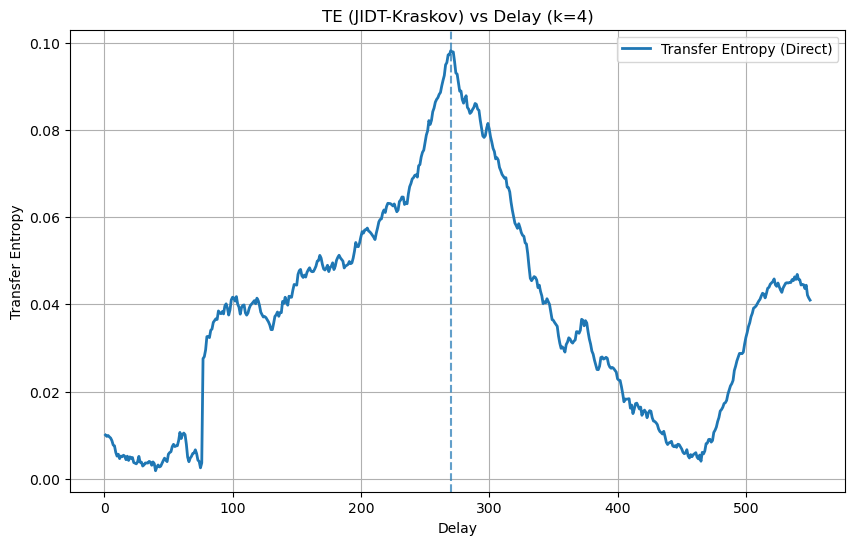

El delay óptimo para k=4 es: 270.000 ms


In [15]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(V1, V2, n_vecinos=4, max_steps=550, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Y ahora en el sentido inverso al del transpaso estructural de información:

Análisis de Tau: 100%|██████████| 700/700 [03:52<00:00,  3.02tau/s]


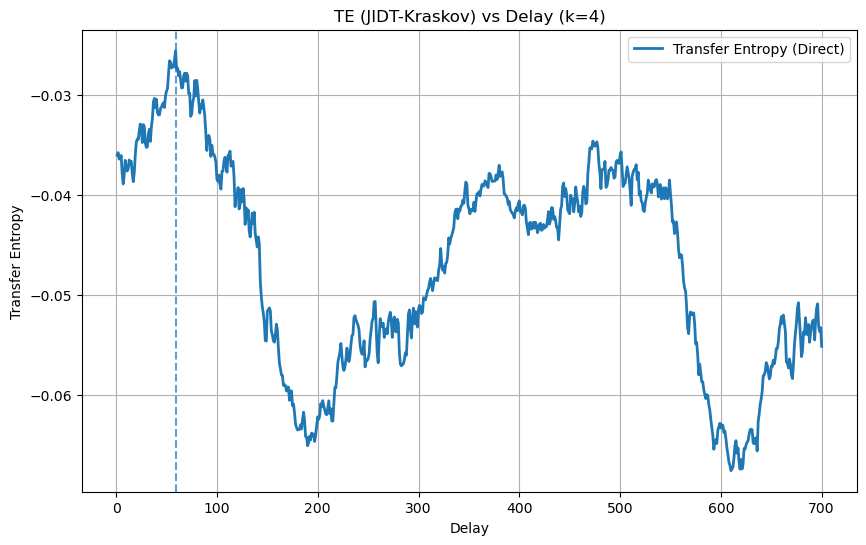

El delay óptimo para k=4 es: 59.000 ms


In [46]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(V2, V1, n_vecinos=4, max_steps=700, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

Observamos un claro pico de intensidad en ambas simulaciones, cuya localización es similar en el tiempo. Este hecho confirma la existencia de un retardo causal en la simulación neuronal, siendo capaces de enmarcarlo en una franja de aproximadamente 20 unidades temporales (0.2 segundos). Este factor muestra la capacidad de los estimadores para detectar la dinámica del flujo (siendo capaces de situarla con precisión en la franja ya mencionada).

Calculando la TE en el sentido inverso al del enlace estructural de las neuronas simuladas (último análisis) observamos que el estimador de TE devuleve valores negativos. Aunque teóricamente la TE es una información mutua condicional y, por definición matemática, debería ser siempre mayor o igual a cero, los estimadores no paramétricos basados en vecinos más cercanos como KSG pueden arrojar valores negativos en la práctica. Como las series están correlacionadas temporalmente, los puntos en el espacio multidimensional no se distribuyen de forma uniforme, sino agrupados. El algoritmo KSG calcula densidades contando vecinos cercanos y usando funciones digamma para estimar volúmenes locales. Al encontrarse con esta distribución no uniforme en una dirección donde no hay una verdadera relación condicional, el cálculo falla sistemáticamente y subestima los valores. Ese error matemático acumulado provoca un sesgo negativo sistemático, dibujando picos negativos que se pueden asociar a comportamientos concretos de la correlación cruzada entre las variables.

A continuación la función `find_optimal_tau_partial_corr` calcula el coeficiente de correlación parcial entre V1 y V2.

In [33]:
def find_optimal_tau_partial_corr(source, target, max_steps=600, factor_bool=False, plot=False, inverse=False, conditional=False):
    """
    Calcula la correlación lineal y la correlación parcial para distintos valores de tau (delay).
    La tercera variable C para la correlación parcial es el pasado inmediato (t-1) del destino.
    
    Retorna:
        tau_values, corr_direct, optimal_tau
    """
    tau_values = np.arange(1, max_steps + 1)
    corr_results = []

    if inverse:
        corr_inverse_results = []
        
    if conditional:
        pcorr_results = []
    
    factor = 5   

    if factor_bool:
        source = source[::factor]
        target = target[::factor]

    def calcular_correlacion_parcial(x, y, c):
        """Aplica la fórmula analítica de correlación parcial de primer orden"""
        r_xy, _ = pearsonr(x, y)
        r_xc, _ = pearsonr(x, c)
        r_yc, _ = pearsonr(y, c)
        
        numerador = r_xy - (r_xc * r_yc)
        denominador = np.sqrt(1 - r_xc**2) * np.sqrt(1 - r_yc**2)
        
        if denominador == 0:
            return 0.0
        return numerador / denominador

    for tau in tqdm(tau_values, desc="Análisis de Correlación", unit="tau"):
        
        # --- Correlación Directa (source -> target) ---
        source_delayed = np.roll(source, tau)   # Desplazamos la fuente V1 en 'tau' pasos hacia el pasado
        x_dir = source_delayed[tau:]   # Cortamos los primeros 'tau' elementos para evitar el efecto circular del roll
        y_dir = target[tau:]
        r_dir, _ = pearsonr(x_dir, y_dir)
        corr_results.append(r_dir)

        # --- Correlación Parcial Directa Condicionada al pasado del Destino ---
        if conditional:
            target_past = np.roll(V2, 1)
            c_dir = target_past[tau:]
            r_partial = calcular_correlacion_parcial(x_dir, y_dir, c_dir)
            pcorr_results.append(r_partial)
            
        # --- Correlación Inversa (V2 -> V1) ---
        if inverse:
            target_delayed = np.roll(target, tau)
            x_inv = target_delayed[tau:]
            y_inv = source[tau:]
            
            r_inv, _ = pearsonr(x_inv, y_inv)
            corr_inverse_results.append(r_inv)

    corr_results = np.array(corr_results)
    if inverse:
        corr_inverse_results = np.array(corr_inverse_results)
    if conditional:
        pcorr_results = np.array(pcorr_results)

    optimal_idx = np.argmax(np.abs(corr_results))
    optimal_tau = tau_values[optimal_idx]
    
    if factor_bool:
        optimal_tau = optimal_tau * factor
        tau_values = tau_values * factor

    # --- Gráfica ---
    if plot:
        plt.figure(figsize=(10, 6))
        plt.plot(tau_values, corr_results, lw=2, label="Correlación Lineal (Directa source → target)")
        plt.scatter(tau_values[optimal_idx], corr_results[optimal_idx], marker="*", s=250, zorder=5, 
                    label=f"Óptimo absoluto: τ={optimal_tau} (r={corr_results[optimal_idx]:.3f})")
        
        if inverse:
            plt.plot(tau_values, corr_inverse_results, color="gray", alpha=0.6, lw=1.8, linestyle="--", label="Correlación Lineal (Inversa target → source)")
        
        if conditional:
            plt.plot(tau_values, pcorr_results, color="red", alpha=0.8, lw=1.8, linestyle="-.", label="Corr. Parcial (cource → target | target_past)")
            
        plt.axvline(tau_values[optimal_idx], linestyle="--", color='orange', alpha=0.7)
        plt.xlabel("Delay (pasos de tiempo reales)")
        plt.ylabel("Coeficiente de Correlación (r)")
        plt.title("Análisis de Correlación Lineal vs Parcial en función del Delay")
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend(loc="best")
        plt.show()

    return tau_values, corr_results, optimal_tau

Análisis de Correlación: 100%|██████████| 500/500 [00:05<00:00, 88.87tau/s]


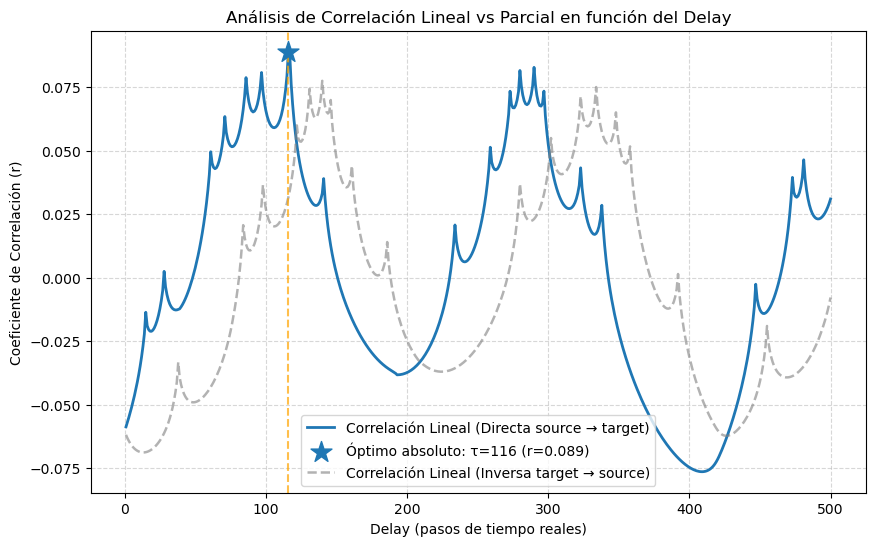

El delay óptimo detectado por la correlación lineal es: 116


In [45]:
tau_ejes, corr_directa, tau_optimo = find_optimal_tau_partial_corr(source=V2, target=V1, max_steps=500, factor_bool=False, plot=True, inverse=True, conditional=False)
print(f"El delay óptimo detectado por la correlación lineal es: {tau_optimo}")

El estimador KSG absorbe esta estructura de dependencia convirtiéndola en un sesgo negativo en la estimación de la TE. Puede ser un reflejo de la estructura cíclica de la correlación cruzada lineal de las series temporales.

Ahora aplicamos un retardo artificial a la sinpaisis de 100 ms. Con eso veremos si obtenemos de vuelta una coherencia temporal respecto a los resultados anteriores. Si bien anteriormente obtuvimos: $\tau=288$ para la Im y  $\tau=270$ para la TE, se espera obetener una relación similar desplazada $100$ unidades.

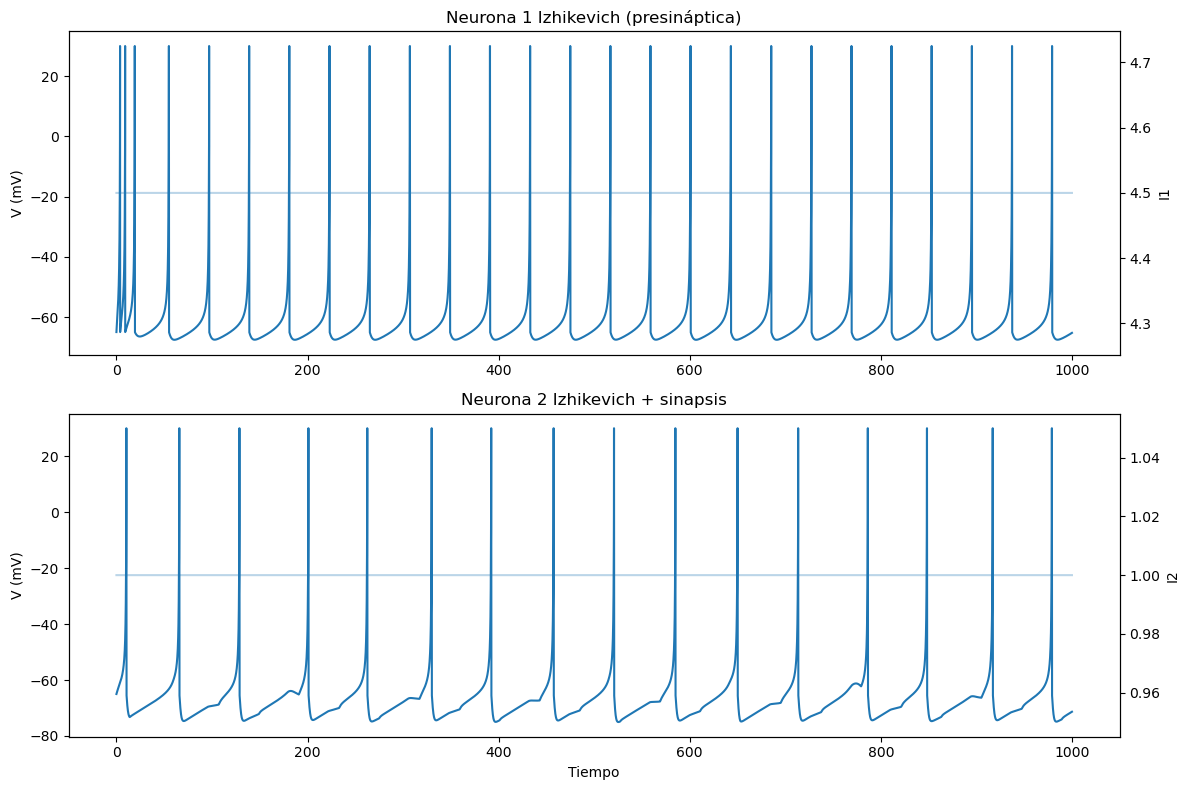

In [35]:
tau = 10.0  #tau = 10.0 --> 0.1 segundos --> 100 ms
V1, V2= mn.izhikevich(T = 1000, a1= 0.01, b1= 0.26, c1= -65.0, d1= 2.0, a2 = 0.02, b2= 0.25, c2 = -65.0, d2 = 6.0, I1_const = 4.5, I2_const = 1.0, g_syn = 0.1, tau_delay = tau, plot = True)

Análisis de Tau: 100%|██████████| 550/550 [00:38<00:00, 14.22lag/s]


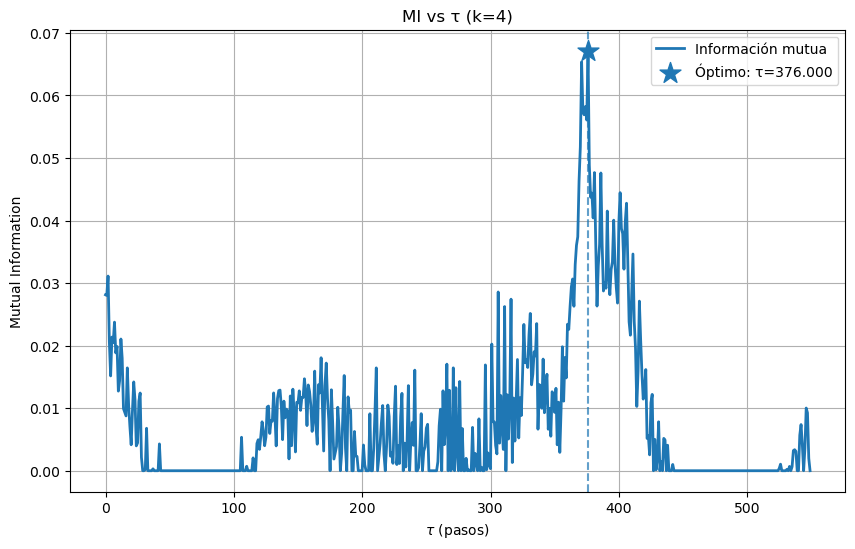

El desplazamiento óptimo para número de vecinos k=4 es: 376


In [17]:
mis, best_tau = find_optimal_tau_MI(V1, V2, n_vecinos=4, max_lags=550, milisegundos = False, plot= True)
print(f"El desplazamiento óptimo para número de vecinos k={4} es: {best_tau}")

Análisis de Tau: 100%|██████████| 550/550 [07:00<00:00,  1.31tau/s]


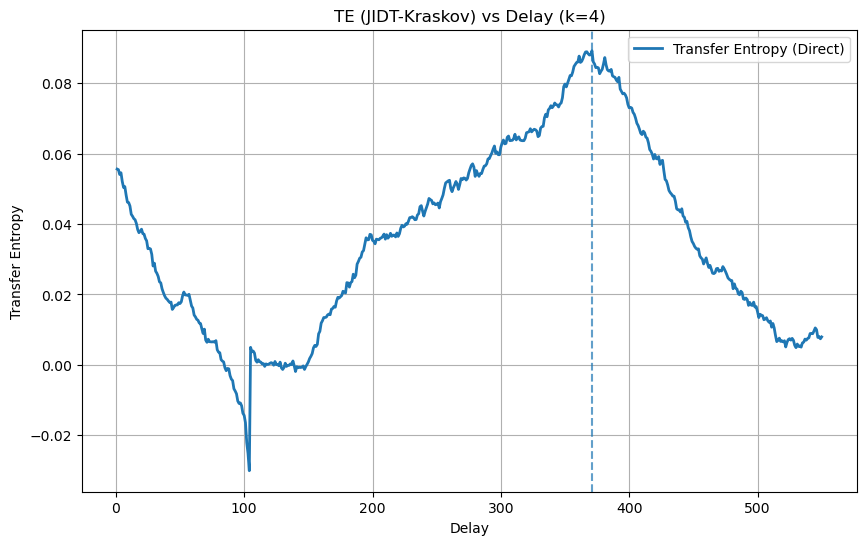

El delay óptimo para k=4 es: 371.000 ms


In [18]:
taus, tes, best_tau = find_optimal_tau_TE_JIDT(V1, V2, n_vecinos=4, max_steps=550, contexto_k=1, contexto_l=1, contexto_c=1, factor_bool= False, plot=True, inverse=False, conditional=False)
print(f"El delay óptimo para k={4} es: {best_tau:.3f} ms")

### Granger Causality

En este apartado se analiza el comportamiento de los criterios de información para la detección del retardo causal presente en los datos, utilizados internamente por el estimador de GC. Se propone un experimento sencillo sobre un VAR($\tau$):

$$
\begin{cases} 
X_t = a X_{t-1} + b Y_{t-\tau} + \varepsilon_t^x \\ 
Y_t = c Y_{t-1} + \varepsilon_t^y. 
\end{cases}
$$

Se fija el valor en $\tau=4$.

In [28]:
# Definición de parámetros teóricos
a, b, c = 0.5, 0.3, 0.7
sig_x2, sig_y2 = 1.0, 1.0
tau = 4

T = 5000

ex = np.random.normal(0, np.sqrt(sig_x2), T)
ey = np.random.normal(0, np.sqrt(sig_y2), T)

Z = np.zeros((T, 2)) # Z[:, 0] es X, Z[:, 1] es Y

for t in range(tau, T):
    # Ecuación para Y: Solo depende de su propio pasado inmediato
    Z[t, 1] = c * Z[t-1, 1] + ey[t]
    
    # Ecuación para X: Depende de su pasado inmediato y de Y con delay tau
    Z[t, 0] = a * Z[t-1, 0] + b * Z[t-tau, 1] + ex[t]

# Ajuste del modelo VAR
data = pd.DataFrame(Z, columns=['X', 'Y'])
modelo_var = VAR(data)

Se puede elegir el orden del modelo VAR manualmente con `select_order` o directamente fijarlo con `fit(ic='bic')` o `fit(maxlags=5)`. 

In [29]:
orden= modelo_var.select_order(maxlags=10)
print(orden.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        1.276       1.278       3.581       1.277
1       0.1371      0.1449       1.147      0.1398
2       0.1200      0.1330       1.127      0.1246
3      0.08735      0.1056       1.091     0.09376
4     0.02945*    0.05296*      1.030*    0.03769*
5      0.02970     0.05843       1.030     0.03977
6      0.03090     0.06484       1.031     0.04280
7      0.03242     0.07159       1.033     0.04615
8      0.03379     0.07819       1.034     0.04935
9      0.03521     0.08483       1.036     0.05260
10     0.03590     0.09074       1.037     0.05512
--------------------------------------------------


Observamos que los estimadores internos son todos capaces de detectar el verdadero retardo causal.